In [1]:
#### situação 1


from time import perf_counter


# Compara resultados e resolve empates:
# menor início e, depois, menor fim.
def escolher_melhor(a, b):
    if a[0] != b[0]:
        return a if a[0] > b[0] else b
    if a[1] != b[1]:
        return a if a[1] < b[1] else b
    return a if a[2] < b[2] else b


# 1. FORÇA BRUTA: O(n²)
def forca_bruta(v):
    n = len(v)
    melhor = None

    for i in range(n):
        soma = 0

        for j in range(i, n):
            soma += v[j]
            candidato = (soma, i, j)

            if melhor is None:
                melhor = candidato
            else:
                melhor = escolher_melhor(
                    melhor, candidato
                )

    return melhor


# Calcula o melhor intervalo que cruza o meio.
def intervalo_cruzando(v, inicio, meio, fim):
    soma = 0
    melhor_esquerda = float("-inf")
    indice_inicio = meio

    for i in range(meio, inicio - 1, -1):
        soma += v[i]

        if soma > melhor_esquerda:
            melhor_esquerda = soma
            indice_inicio = i
        elif soma == melhor_esquerda:
            indice_inicio = min(indice_inicio, i)

    soma = 0
    melhor_direita = float("-inf")
    indice_fim = meio + 1

    for j in range(meio + 1, fim + 1):
        soma += v[j]

        if soma > melhor_direita:
            melhor_direita = soma
            indice_fim = j
        elif soma == melhor_direita:
            indice_fim = min(indice_fim, j)

    return (
        melhor_esquerda + melhor_direita,
        indice_inicio,
        indice_fim
    )


# 2. DIVISÃO E CONQUISTA: O(n log n)
def dc_recursiva(v, inicio, fim):
    # Caso base: apenas um elemento.
    if inicio == fim:
        return (v[inicio], inicio, fim)

    meio = (inicio + fim) // 2

    esquerda = dc_recursiva(v, inicio, meio)
    direita = dc_recursiva(v, meio + 1, fim)

    cruzando = intervalo_cruzando(
        v, inicio, meio, fim
    )

    melhor = escolher_melhor(esquerda, direita)
    melhor = escolher_melhor(melhor, cruzando)

    return melhor


def divisao_e_conquista(v):
    if not v:
        raise ValueError("O vetor não pode ser vazio.")

    return dc_recursiva(v, 0, len(v) - 1)


# 3. TESTES DOS CASOS DE BORDA
def testar_casos():
    casos = [
        ([-8, -3, -6, -2, -5], (-2, 3, 3)),
        ([7], (7, 0, 0)),
        ([1, -1, 1], (1, 0, 0)),
        ([2, -2, 2], (2, 0, 0)),
    ]

    for vetor, esperado in casos:
        assert forca_bruta(vetor) == esperado
        assert divisao_e_conquista(vetor) == esperado

    print("Todos os testes passaram!")


# 4. LEITURA DA ENTRADA E EXECUÇÃO
if __name__ == "__main__":
    testar_casos()

    n = int(input())
    vetor = list(map(int, input().split()))

    if n <= 0 or len(vetor) != n:
        raise ValueError("Entrada inválida.")

    inicio = perf_counter()
    resultado_fb = forca_bruta(vetor)
    tempo_fb = perf_counter() - inicio

    inicio = perf_counter()
    resultado_dc = divisao_e_conquista(vetor)
    tempo_dc = perf_counter() - inicio

    print("\nForça bruta")
    print("Soma máxima:", resultado_fb[0])
    print("Índice inicial:", resultado_fb[1])
    print("Índice final:", resultado_fb[2])
    print(f"Tempo: {tempo_fb:.8f} segundos")

    print("\nDivisão e conquista")
    print("Soma máxima:", resultado_dc[0])
    print("Índice inicial:", resultado_dc[1])
    print("Índice final:", resultado_dc[2])
    print(f"Tempo: {tempo_dc:.8f} segundos")

    assert resultado_fb == resultado_dc
    print("\nResultados iguais nas duas implementações.")


Todos os testes passaram!
5
-2 4 -1 5 -3

Força bruta
Soma máxima: 8
Índice inicial: 1
Índice final: 3
Tempo: 0.00003889 segundos

Divisão e conquista
Soma máxima: 8
Índice inicial: 1
Índice final: 3
Tempo: 0.00002345 segundos

Resultados iguais nas duas implementações.


Teste com 100 pontos concluído.
Teste com 200 pontos concluído.
Teste com 400 pontos concluído.
Teste com 800 pontos concluído.
Teste com 1600 pontos concluído.
Teste com 3200 pontos concluído.
Teste com 6400 pontos concluído.

TABELA DE RESULTADOS


,Quantidade de pontos,Força bruta (s),Divisão e conquista (s)
0,100,0.001641,0.000451
1,200,0.006381,0.000977
2,400,0.027901,0.002399
3,800,0.112277,0.005204
4,1600,0.441958,0.010163
5,3200,2.156520,0.028051
6,6400,8.312174,0.053247


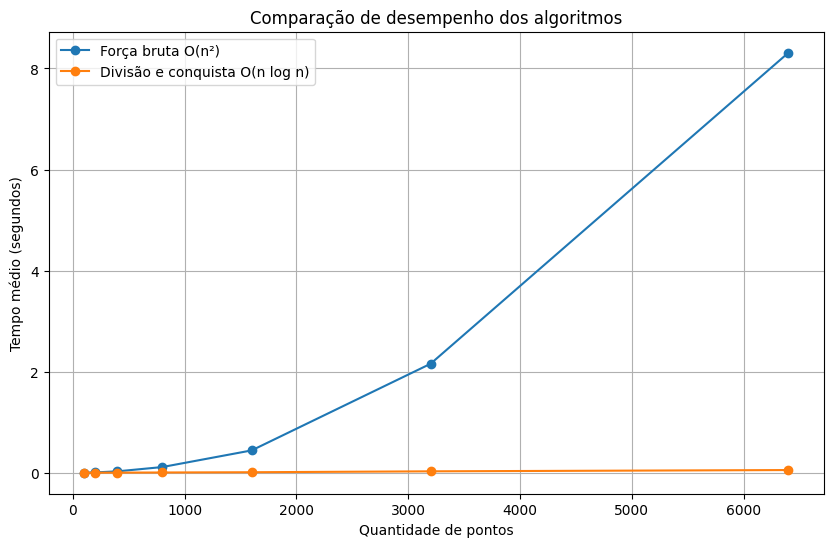

Todos os testes passaram!

Quantidade de pontos: 3
Coordenadas do ponto 1 (x y): 0 0
Coordenadas do ponto 2 (x y): 3 4
Coordenadas do ponto 3 (x y): 1 1

--- FORÇA BRUTA ---
Pontos mais próximos: ((0.0, 0.0), (1.0, 1.0))
Distância mínima: 1.4142135623730951
Tempo: 0.00001703 segundos

--- DIVISÃO E CONQUISTA ---
Pontos mais próximos: ((0.0, 0.0, 0), (1.0, 1.0, 2))
Distância mínima: 1.4142135623730951
Tempo: 0.00002308 segundos

As duas implementações encontraram a mesma distância.
Teste com 100 pontos concluído.
Teste com 200 pontos concluído.
Teste com 400 pontos concluído.
Teste com 800 pontos concluído.
Teste com 1600 pontos concluído.
Teste com 3200 pontos concluído.
Teste com 6400 pontos concluído.

TABELA DE RESULTADOS


,Quantidade de pontos,Força bruta (s),Divisão e conquista (s)
0,100,0.001749,0.000478
1,200,0.006575,0.000946
2,400,0.027943,0.002623
3,800,0.114389,0.005098
4,1600,0.458411,0.010469
5,3200,2.219575,0.027972
6,6400,8.618832,0.053710


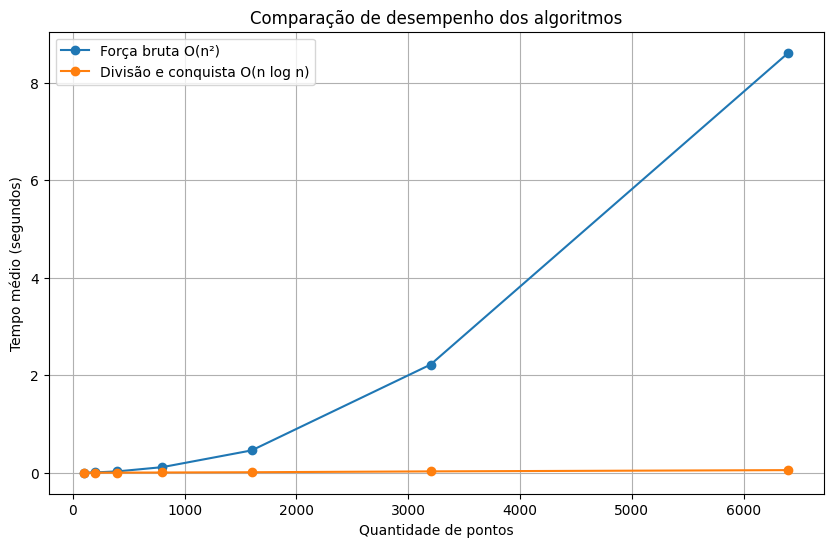

In [3]:
#situação 2

import random
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter



# 1. FORÇA BRUTA - O(n²)


def forca_bruta(pontos):
    melhor = None

    for i in range(len(pontos)):
        for j in range(i + 1, len(pontos)):
            p1 = pontos[i]
            p2 = pontos[j]

            distancia2 = (
                (p1[0] - p2[0]) ** 2
                + (p1[1] - p2[1]) ** 2
            )

            candidato = (distancia2, p1, p2)

            if melhor is None or distancia2 < melhor[0]:
                melhor = candidato

    return melhor


# 2. FUNÇÕES AUXILIARES

def distancia2(p1, p2):
    return (
        (p1[0] - p2[0]) ** 2
        + (p1[1] - p2[1]) ** 2
    )


def escolher_melhor(a, b):
    if a is None:
        return b

    if b is None:
        return a

    if a[0] <= b[0]:
        return a

    return b

# 3. DIVISÃO E CONQUISTA - O(n log n)


def dc_recursiva(px, py):
    n = len(px)

    # Caso base: compara diretamente até 3 pontos.
    if n <= 3:
        return forca_bruta(px)

    # Divide os pontos pela mediana de x.
    meio = n // 2
    esquerda_x = px[:meio]
    direita_x = px[meio:]

    ids_esquerda = {p[2] for p in esquerda_x}

    esquerda_y = [
        p for p in py if p[2] in ids_esquerda
    ]

    direita_y = [
        p for p in py if p[2] not in ids_esquerda
    ]

    # Resolve cada metade recursivamente.
    melhor_esquerda = dc_recursiva(
        esquerda_x, esquerda_y
    )

    melhor_direita = dc_recursiva(
        direita_x, direita_y
    )

    melhor = escolher_melhor(
        melhor_esquerda, melhor_direita
    )

    delta2 = melhor[0]
    linha = direita_x[0][0]

    # Seleciona pontos próximos à linha divisória.
    faixa = [
        p for p in py
        if (p[0] - linha) ** 2 <= delta2
    ]

    # A faixa já está ordenada por y.
    # Compara cada ponto com, no máximo, 7 seguintes.
    for i in range(len(faixa)):
        limite = min(i + 8, len(faixa))

        for j in range(i + 1, limite):
            diferenca_y = faixa[j][1] - faixa[i][1]

            # Os pontos seguintes estão ordenados por y.
            if diferenca_y ** 2 > melhor[0]:
                break

            d2 = distancia2(faixa[i], faixa[j])

            if d2 < melhor[0]:
                melhor = (
                    d2, faixa[i], faixa[j]
                )

    return melhor


def divisao_e_conquista(pontos):
    if len(pontos) < 2:
        raise ValueError(
            "São necessários pelo menos dois pontos."
        )

    # Cada ponto recebe um identificador único,
    # para separar corretamente as metades.
    pontos_id = [
        (x, y, i)
        for i, (x, y) in enumerate(pontos)
    ]

    # Ordenações iniciais usando a biblioteca padrão.
    px = sorted(pontos_id, key=lambda p: (p[0], p[1], p[2]))
    py = sorted(pontos_id, key=lambda p: (p[1], p[0], p[2]))

    return dc_recursiva(px, py)



# 4. TESTES


def testar_casos():
    casos = [
        [(0, 0), (3, 4)],
        [(5, 5), (5, 5)],
        [(0, 0), (1, 0), (2, 0), (3, 0)],
        [(0, 0), (2, 0), (1, 2), (1, -2)],
        [(-5, -5), (-4, -4), (10, 10)],
    ]

    for pontos in casos:
        resultado_fb = forca_bruta(pontos)
        resultado_dc = divisao_e_conquista(pontos)

        assert resultado_fb[0] == resultado_dc[0], (
            f"Resultados diferentes para {pontos}"
        )

    print("Todos os testes passaram!")


# 5. ANÁLISE EXPERIMENTAL

def analisar_desempenho():

    tamanhos = [100, 200, 400, 800, 1600, 3200, 6400]

    resultados = []

    for n in tamanhos:

        # Gera n pontos diferentes
        random.seed(42)

        valores = random.sample(range(100_000_000), n)

        pontos = [
            (valor % 10000, valor // 10000)
            for valor in valores
        ]

        tempos_fb = []
        tempos_dc = []

        # Executa cada algoritmo 5 vezes
        for repeticao in range(5):

            # Força bruta
            inicio = perf_counter()
            resultado_fb = forca_bruta(pontos)
            fim = perf_counter()

            tempos_fb.append(fim - inicio)

            # Divisão e conquista
            inicio = perf_counter()
            resultado_dc = divisao_e_conquista(pontos)
            fim = perf_counter()

            tempos_dc.append(fim - inicio)

            # Confere se encontraram a mesma distância
            assert resultado_fb[0] == resultado_dc[0]

        # Calcula a média dos tempos
        media_fb = sum(tempos_fb) / 5
        media_dc = sum(tempos_dc) / 5

        resultados.append({
            "Quantidade de pontos": n,
            "Força bruta (s)": media_fb,
            "Divisão e conquista (s)": media_dc
        })

        print(f"Teste com {n} pontos concluído.")

    # Cria a tabela
    tabela = pd.DataFrame(resultados)

    print("\nTABELA DE RESULTADOS")
    display(tabela)

    # Cria o gráfico
    plt.figure(figsize=(10, 6))

    plt.plot(
        tabela["Quantidade de pontos"],
        tabela["Força bruta (s)"],
        marker="o",
        label="Força bruta O(n²)"
    )

    plt.plot(
        tabela["Quantidade de pontos"],
        tabela["Divisão e conquista (s)"],
        marker="o",
        label="Divisão e conquista O(n log n)"
    )

    plt.xlabel("Quantidade de pontos")
    plt.ylabel("Tempo médio (segundos)")
    plt.title("Comparação de desempenho dos algoritmos")
    plt.legend()
    plt.grid(True)
    plt.show()


# Executa a análise experimental
analisar_desempenho()



# 6. EXECUÇÃO PRINCIPAL


if __name__ == "__main__":
    testar_casos()

    n = int(input("\nQuantidade de pontos: "))

    if n < 2:
        raise ValueError(
            "Informe pelo menos dois pontos."
        )

    pontos = []

    for i in range(n):
        x, y = map(
            float,
            input(f"Coordenadas do ponto {i + 1} (x y): ").split()
        )
        pontos.append((x, y))

    inicio = perf_counter()
    resultado_fb = forca_bruta(pontos)
    tempo_fb = perf_counter() - inicio

    inicio = perf_counter()
    resultado_dc = divisao_e_conquista(pontos)
    tempo_dc = perf_counter() - inicio

    print("\n--- FORÇA BRUTA ---")
    print("Pontos mais próximos:", resultado_fb[1:])
    print("Distância mínima:", math.sqrt(resultado_fb[0]))
    print(f"Tempo: {tempo_fb:.8f} segundos")

    print("\n--- DIVISÃO E CONQUISTA ---")
    print("Pontos mais próximos:", resultado_dc[1:])
    print("Distância mínima:", math.sqrt(resultado_dc[0]))
    print(f"Tempo: {tempo_dc:.8f} segundos")

    assert resultado_fb[0] == resultado_dc[0]
    print("\nAs duas implementações encontraram a mesma distância.")

    analisar_desempenho()
